# Strukturierter Output

In diesem Notebook werden wir ausschliesslich mit API Schnittstellen arbeiten. D.h. der Zugriff auf LLMs geschieht programmatisch.

Ein LLM liefert Text. Damit wir es als Softwarekomponente verwenden können, muss anderer Code diesen Text zuverlässig weiterverarbeiten können. In diesem Notebook extrahieren wir die Felder eines Boarding Pass (ein Bild) und machen den Output schrittweise kontrollierter:

1. Extraktion als Freitext
2. Im Prompt nach JSON fragen
3. JSON-Modus
4. Ein JSON-Schema, von der API erzwungen
5. Ein Pydantic-Modell, zur Laufzeit validiert
6. Kosten

Der Boarding Pass deckt alle Basistypen ab, die ein Schema verlangen kann: Strings, eine Ganzzahl, einen Boolean, ein Datum und ein Enum. In den Übungen wenden Sie dieselben Schritte auf die medizinischen Rechnungen an und fügen einen weiteren Typ hinzu: `tags`, eine Liste von Werten aus einer festen Menge (ein Array von Enum-Werten). Das `MedicalInvoice`-Objekt, das Sie am Ende erhalten, ist der Input aller späteren Module.

## Warum JSON?

- **Interoperabilität**: Jede Programmiersprache kann es parsen.
- **Hierarchisch**: Verschachtelte Objekte und Listen bilden reale Daten ab (eine Rechnung mit mehreren Behandlungen, eine Liste von Zitaten).
- **Validierbar**: Ein Schema legt genau fest, welche Felder von welchem Typ vorhanden sein müssen.

In [ ]:
# Setup - Kann ignoriert werden
import base64
import json
import os
import re
import functools
from datetime import date
from enum import Enum
from pathlib import Path
from dotenv import load_dotenv
from openai import OpenAI
from io import BytesIO

from IPython.display import Image, display
from pydantic import BaseModel, Field, ValidationError

import pypdfium2 as pdfium

CHAT_MODEL = "gpt-6-luna"  # text, vision and tool calling
MODEL = CHAT_MODEL
# OLD_MODEL =   # Older text + vision model to showcase failure modes
EMBEDDING_MODEL = "text-embedding-3-small"


# walk up from the working directory to the repo root (the folder with .git)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())
DATA_DIR = REPO_ROOT / "backend" / "notebooks" / "data"
REQUEST_DIR = DATA_DIR / "request"
GENERATED_DIR = DATA_DIR / "generated" 
# USD per 1M tokens. Check https://openai.com/api/pricing/ before using these for a real budget.
PRICES = {
    "gpt-6-luna": {"input": 0.10, "cached_input": 0.01, "output": 0.50},
    "gpt-4o-mini": {"input": 0.15, "cached_input": 0.075, "output": 0.60},
    "text-embedding-3-small": {"input": 0.02, "cached_input": 0.02, "output": 0.0},
}


def usage_cost(usages, model: str = CHAT_MODEL) -> dict:
    """Tokens and cost (USD) of one usage object or a list of them.

    Accepts the `usage` of a Responses API call (input/output tokens, of which cached and reasoning
    tokens) and of an embeddings call (prompt tokens only).
    """
    if not isinstance(usages, (list, tuple)):
        usages = [usages]
    input_tokens = cached_tokens = output_tokens = reasoning_tokens = 0
    for u in usages:
        if hasattr(u, "input_tokens"):  # Responses API
            input_tokens += u.input_tokens
            output_tokens += u.output_tokens
            cached_tokens += getattr(u.input_tokens_details, "cached_tokens", 0) or 0
            reasoning_tokens += getattr(u.output_tokens_details, "reasoning_tokens", 0) or 0
        else:  # embeddings
            input_tokens += u.prompt_tokens
    price = PRICES[model]
    cost = ((input_tokens - cached_tokens) * price["input"]
            + cached_tokens * price["cached_input"]
            + output_tokens * price["output"]) / 1e6
    return {
        "input_tokens": input_tokens,
        "cached_tokens": cached_tokens,
        "output_tokens": output_tokens,  # includes the reasoning tokens
        "reasoning_tokens": reasoning_tokens,
        "cost_usd": cost,
    }


def print_cost(usages, model: str = CHAT_MODEL) -> None:
    c = usage_cost(usages, model)
    print(f"Input tokens:  {c['input_tokens']} (cached: {c['cached_tokens']})")
    print(f"Output tokens: {c['output_tokens']} (reasoning: {c['reasoning_tokens']})")
    print(f"Estimated cost: ${c['cost_usd']:.6f}")

@functools.cache
def get_client() -> OpenAI:
    """The OpenAI client, created and cached on first use.

    Reads LLM_API_KEY and LLM_BASE_URL from <repo>/.env.local, the same variables the backend uses.
    An empty LLM_BASE_URL means OpenAI itself.
    """
    load_dotenv(REPO_ROOT / ".env.local")
    return OpenAI(api_key=os.environ["LLM_API_KEY"], base_url=os.getenv("LLM_BASE_URL") or None)


def image_to_data_url(path: Path) -> str:
    """A PNG/JPEG file as a base64 data URL, for the `input_image` parts of a Responses API call."""
    path = Path(path)
    mime = "image/jpeg" if path.suffix.lower() in {".jpg", ".jpeg"} else "image/png"
    return f"data:{mime};base64," + base64.b64encode(path.read_bytes()).decode()

def pdf_to_images(path: Path, dpi: int = 150) -> list[bytes]:
    """Render every page of a PDF as PNG bytes (150 dpi is sharp enough to read small print)."""
    pdf = pdfium.PdfDocument(path)
    images = []
    for page in pdf:
        buffer = BytesIO()
        page.render(scale=dpi / 72).to_pil().save(buffer, format="PNG")  # PDF points are 1/72 inch
        images.append(buffer.getvalue())
    return images


def pdf_to_data_urls(path: Path, dpi: int = 150) -> list[str]:
    """One data URL per page, for the `input_image` parts of a Responses API call."""
    return ["data:image/png;base64," + base64.b64encode(png).decode() for png in pdf_to_images(path, dpi)]


def save_pdf_pages(path: Path, out_dir: Path = GENERATED_DIR, dpi: int = 150) -> list[Path]:
    """Write each page as <pdf name>_page1.png, _page2.png, ... and return the paths (e.g. to display them)."""
    path = Path(path)
    out_dir.mkdir(parents=True, exist_ok=True)
    paths = []
    for number, png in enumerate(pdf_to_images(path, dpi), start=1):
        paths.append(out_dir / f"{path.stem}_page{number}.png")
        paths[-1].write_bytes(png)
    return paths

client = get_client()

## Der Boarding Pass - Beispiel

`data/boarding_pass/boarding_pass.png` ist ein Beispiel-Boarding-Pass für einen Flug von Genf nach Zürich. Das Modell liest Bilder direkt: Wir senden das PNG als Base64-Data-URL (`image_to_data_url`) zusammen mit unserem Text-Prompt.

In [ ]:
BOARDING_PASS = DATA_DIR / "boarding_pass" / "boarding_pass.png"
display(Image(filename=BOARDING_PASS, width=800))

def image_input(prompt: str, path: Path = BOARDING_PASS) -> list[dict]:
    """A user message with our prompt and an image."""
    return [{"role": "user", "content": [
        {"type": "input_text", "text": prompt},
        {"type": "input_image", "image_url": image_to_data_url(path)},
    ]}]

## 1. Standard-Extraktion

Wir fragen nach den Feldern, ohne Angabe eines Formats. Dies könnten wir genau so gut in ChatGPT im UI machen.

In [ ]:
PROMPT = """You are a document processing assistant. Extract the following details from this boarding pass:
- Passenger name
- Origin city
- Destination city
- Departure date
- Seat row and seat letter
- Whether a cabin bag is allowed
- Travel class"""

response = client.responses.create(model=MODEL, input=image_input(PROMPT))
print(response.output_text)

Das Modell hat die Felder extrahiert, aber als Freitext, dessen Aufbau sich von Aufruf zu Aufruf ändern kann. Code, der ihn weiterverarbeitet, müsste jedes Mal versuchen, eine nicht standardisierte Eingabe zu parsen.

## 2. Bekommen wir JSON, wenn wir einfach danach fragen?
### Ein Vergleich zweier Modelle, um zu zeigen wie der Output sich unterscheiden kann.

Hier verwenden wir `gpt-4o-mini`, ein älteres Modell, im Vergleich zu `gpt-6-luna`, das im Rest der Übung verwendet wird. Das ältere Modell ist bei manchen Aufgaben wie der strukturierten Extraktion im Allgemeinen weniger zuverlässig. Auch wenn dies heute *viel* seltener vorkommt, ist es trotzdem nützlich, solche Fälle zu kennen.

In [ ]:
response = client.responses.create(model="gpt-4o-mini", input=image_input(PROMPT + "\n\nGive me the result in JSON format."))

print(response.output_text)

In [ ]:
# Die folgende Zeile wird nicht funktionieren. Wir probieren, das generierte json auszupacken,
# aber das LLM hat nicht das Standardformat retourniert, sondern noch zusätzliche Zeichen angehängt.
json.loads(response.output_text)

Ein Modell, das im Prompt nach JSON gefragt wird, verpackt es oft in einen Markdown-Codeblock (`` ```json ... ``` ``), den `json.loads` ablehnt. Nichts garantiert das Format: Wir müssen den Text selbst bereinigen.

In [ ]:
# Wir bereinigen den Text und dann lädt es.
json_str = re.sub(r"^```(?:json)?\s*", "", response.output_text.strip())
json_str = re.sub(r"\s*```$", "", json_str)
json.loads(json_str)

Und hier wechseln wir zurück zu `MODEL`, damit sollte es diesmal problemlos funktionieren. Dieses Model weiss, dass es Json nicht mit Zusatzzeichen verpacken sollte.

In [ ]:
response = client.responses.create(model=MODEL, input=image_input(PROMPT + "\n\nGive me the result in JSON format."))
print(response.output_text)

In [ ]:
# Newer model handles this without problems
json.loads(response.output_text)

## 3. JSON-Modus

Die API kann erzwingen, dass der Output gültiges JSON ist: `text={"format": {"type": "json_object"}}`. Der Prompt muss trotzdem JSON erwähnen, da wir die Anweisung übergeben müssen JSON zu kreieren.

In [ ]:
response = client.responses.create(
    model=MODEL,
    input=image_input(PROMPT + "\n\nGive me the result in JSON format."),
    text={"format": {"type": "json_object"}},
)
json.loads(response.output_text)

Der Output lässt sich jetzt immer parsen. Aber seine *Form* bleibt dem Modell überlassen: Die Schlüssel können `passenger_name`, `Passenger name` oder `passengerName` heissen, das Datum `14NOV26` oder `2026-11-14`, das Kabinengepäck `true` oder `"1 x 8 kg included"`. Führen Sie die Zelle zweimal aus und vergleichen Sie.

## 4. Ein JSON-Schema

Wir übergeben ein JSON-Schema, das genau beschreibt, welche Schlüssel welchen Typs wir wollen. Mit `"strict": True` **schränkt die API die Generierung** auf das Schema ein. Der Strict-Modus verlangt, dass jede Property in `required` aufgeführt ist und `additionalProperties: false` gesetzt ist; ein optionaler Wert wird als Typ ausgedrückt, der auch `null` erlaubt.

Jedes Feld des Boarding Pass zeigt einen Typ:

| Feld | JSON-Schema | Auf dem Pass |
|---|---|---|
| `passenger_name`, `origin`, `destination`, `seat_letter` | `{"type": "string"}` | `MEIER / SOPHIE`, `GENEVA GVA`, das `A` von `23A` |
| `seat_row` | `{"type": "integer"}` | die `23` von `23A` |
| `cabin_bag_allowed` | `{"type": "boolean"}` | `1 x 8 kg INCLUDED` |
| `departure_date` | `{"type": "string", "format": "date"}` | `14NOV26` |
| `travel_class` | `{"type": "string", "enum": ["Economy", "Business"]}` | `ECONOMY` |

JSON kennt keinen Datumstyp: Ein Datum ist ein String, und `"format": "date"` verlangt ein ISO-8601-Datum (`YYYY-MM-DD`). Ein `enum` beschränkt einen Wert auf eine feste Liste. Eine `description` sagt dem Modell, wie ein Feld auszufüllen ist, zum Beispiel die Reihenfolge der Namensbestandteile.

In [ ]:
schema = {
    "type": "object",
    "properties": {
        "passenger_name": {"type": "string", "description": "As: Firstname Middlename Lastname"},
        "origin": {"type": "string", "description": "City of origin."},
        "destination": {"type": "string", "description": "Destination city."},
        "departure_date": {"type": "string", "format": "date", "description": "ISO-8601 formatted date; YYYY-MM-DD."},
        "seat_row": {"type": "integer"},
        "seat_letter": {"type": "string"},
        "cabin_bag_allowed": {"type": "boolean"},
        "travel_class": {"type": "string", "enum": ["Economy", "Business", "First", "Other"]},
    },
    "required": ["passenger_name", "origin", "destination", "departure_date", "seat_row", "seat_letter", "cabin_bag_allowed", "travel_class"],
    "additionalProperties": False,
}

response = client.responses.create(
    model=MODEL,
    input=image_input("Extract the boarding pass fields."),
    text={"format": {"type": "json_schema", "name": "BoardingPass", "schema": schema, "strict": True}},
)
json.loads(response.output_text)

Die Schlüssel und Typen stimmen jetzt immer mit dem Schema überein: `seat_row` ist eine Zahl, `cabin_bag_allowed` ist `true` oder `false`, und `travel_class` ist genau `"Economy"` oder `"Business"` (nie `"ECONOMY"` oder `"Eco"`). Die *Werte* können trotzdem falsch sein: Das Schema garantiert die Form, nicht die Wahrheit.

## 5. Pydantic

JSON-Schemas von Hand zu schreiben ist mühsam. Ein [Pydantic](https://docs.pydantic.dev/latest/)-Modell beschreibt dasselbe als Python-Klasse: `client.responses.parse(text_format=[Pydantic-Klasse]])` macht daraus ein striktes Schema und **validiert** die Antwort zurück in ein Objekt. `output_parsed` ist ein `BoardingPass` (Die Pydantic-Klasse, die wir definiert haben), kein String (kein Text).

Die Python-Typen entsprechen den JSON-Typen: `str` → `string`, `int` → `integer`, `bool` → `boolean`, `date` → `string` mit `"format": "date"`. Zusätzlich haben wir die `Travel Class` Klasse definiert, was uns erlaubt die Antwort in vordefinierte Reisetypen (Economy, Business, First) einzuschränken. Ein Enum ist eine Python-`Enum`-Klasse. Weil `TravelClass` von `str` erbt, ist ein Member gleich seinem Wert (`TravelClass.ECONOMY == "Economy"`).

In [ ]:
class TravelClass(str, Enum):
    ECONOMY = "Economy"
    BUSINESS = "Business"
    FIRST = "First"
    OTHER = "Other"


class BoardingPass(BaseModel):
    passenger_name: str = Field(description="As: Firstname Middlename Lastname")
    origin: str = Field(description="City of origin as IATA airport code, e.g. KIX for Kansai International")
    destination: str = Field(description="Destination city as IATA airport code, e.g. KIX for Kansai International")
    departure_date: date = Field(description="ISO-8601 formatted date; YYYY-MM-DD.")
    seat_row: int
    seat_letter: str
    cabin_bag_allowed: bool
    travel_class: TravelClass = Field(description="use the most fitting class, e.g. 'economy flex' is an economy class ticket." \
    "'Other' class should only be used when the class on the ticket cannot specifically be matched with. either economy, business"
    "or first e.g. 'fly free class'.")


response = client.responses.parse(
    model=MODEL,
    input=image_input("Extract the boarding pass fields into the provided schema."),
    text_format=BoardingPass,
)

boarding_pass = response.output_parsed
boarding_pass

Das von Pydantic generierte JSON-Schema entspricht dem von Hand geschriebenen recht gut. Es gibt jedoch einige Unterschiede:

- Zusätzlich zu `type` hat das Pydantic-Schema einen `title`, der lediglich eine grossgeschriebene Umformung des Feldnamens ist.
- Das Enum wird in einem separaten `$defs`-Feld definiert und dann mit `$ref` referenziert.

In [ ]:
pydantic_schema = BoardingPass.model_json_schema()
for field in ["departure_date", "seat_row", "cabin_bag_allowed", "travel_class"]:
    print(f"{field}: hand-written {schema['properties'][field]}")
    print(f"{' ' * len(field)}  Pydantic     {pydantic_schema['properties'][field]}")
print("$defs:", pydantic_schema["$defs"])

Jedes Feld kommt als Python-Wert des richtigen Typs an, sodass wir direkt damit rechnen können, ohne alle Werte in einen richtigen Typen umwandeln zu müssen. Sprich, wenn wir Zahlen zurückbekommen können wir in Python direkt damit weiterrechnen.

In [ ]:
print("Departs on a", boarding_pass.departure_date.strftime("%A"))  # a datetime.date, not a string
print("Window seat:", boarding_pass.seat_letter in {"A", "F"})
print("Rows from the front:", boarding_pass.seat_row - 1)  # an int
if boarding_pass.travel_class is TravelClass.ECONOMY and boarding_pass.cabin_bag_allowed:
    print("Economy with a cabin bag")

### Fehlermodi

Ein Schema macht den Output *parsebar*, aber nicht *korrekt*. Die typischen Fehler:

- **Halluzinierte Werte**: Ein Feld, das auf dem Bild nicht zu sehen ist, wird mit einer plausiblen Vermutung gefüllt. Vorallem, wenn der Datentyp zu restriktiv ist.
- **Verwechselte Werte**: Der Pass enthält mehrere Zahlen (`23A`, `A12`, `042`, `2805`); das Modell kann das Gate oder die Sequenznummer in `seat_row` eintragen.
- **Unleserliche Eingabe**: Ohne die Anweisung «verwende null statt zu raten» (und ein Feld, das null erlaubt) muss das Modell einen Wert erfinden. Das sehen Sie in Übung 3 an einer Rechnung.
- **Schema-Verletzungen**, wenn das Format nicht erzwungen wird (Abschnitte 2–3): fehlende Schlüssel, andere Namen, `"23A"` als Sitzreihe, `"14NOV26"` als Datum.

Pydantic fängt die letzte Art zur Laufzeit ab (`BoardingPass.model_validate_json(...)` löst einen `ValidationError` aus); die ersten drei erfordern eine Auswertung gegen Ground Truth (M05).

In [ ]:
# Pydantic wirft einen Fehler wenn der Datentyp nicht mit der Vorgabe übereinstimmt.
for bad in [{"seat_row": "23A"}, {"departure_date": "14NOV26"}, {"travel_class": "First"}, {"cabin_bag_allowed": "1 x 8 kg"}]:
    try:
        BoardingPass.model_validate({**boarding_pass.model_dump(), **bad})
    except ValidationError as e:
        print(type(e).__name__, e, "\n")

## 6. Kosten

Jeder Aufruf wird pro Token abgerechnet: der Input (Prompt **und Bild**) und der Output (einschliesslich der Reasoning-Tokens, die das Modell nicht anzeigt). `usage_cost` aus `workshop_notebooks` liest die `usage` einer Antwort und wendet die Preise aus `workshop_notebooks/costs.py` an.

### Prompt Caching

Beginnt ein Prompt gleich wie ein kürzlich gesendeter (hier: dasselbe Bild mit demselben Text), muss der Anbieter diesen Anfang nicht neu verarbeiten. Er nimmt das Zwischenergebnis aus einem Cache und verrechnet diese Tokens zu einem Bruchteil des Preises (bei `gpt-6-luna` 10 %). OpenAI macht das automatisch ab etwa 1024 Tokens. Der Cache bleibt nur wenige Minuten erhalten.

Deshalb gehört der gleichbleibende Teil (Systemprompt, Anweisungen, Schema) an den Anfang des Prompts und der variable Teil (das jeweilige Dokument) ans Ende.

In [ ]:
print_cost(response.usage)

c = usage_cost(response.usage)
price = PRICES[MODEL]
# Input = uncached tokens at the full price + cached tokens at the discounted price
input_cost = ((c["input_tokens"] - c["cached_tokens"]) * price["input"]
              + c["cached_tokens"] * price["cached_input"]) / 1e6
output_cost = c["output_tokens"] * price["output"] / 1e6
print(f"Input share of the cost: {input_cost / c['cost_usd']:.0%}")

# The same image was sent several times above, so most of the input comes from the prompt cache.
# Without the cache, the input would cost:
uncached_input_cost = c["input_tokens"] * price["input"] / 1e6
print(f"Input share without the cache: {uncached_input_cost / (uncached_input_cost + output_cost):.0%}")

Das Bild macht einen grossen Teil des Inputs aus. Bei jedem Aufruf ein langes Dokument (ein 50-seitiges Policen-PDF) zu senden, wäre viel teurer: In der RAG Prototyping Session zeigen wir, wie man nur die relevanten Passagen sendet.

## Takeaways

- Im Prompt nach JSON zu fragen reicht nicht; der JSON-Modus garantiert gültiges JSON, nicht die richtigen Schlüssel.
- Ein striktes JSON-Schema (oder ein Pydantic-Modell, das eines generiert) garantiert die Form: die Schlüssel, die Typen (`string`, `integer`, `boolean`, ein `date`-String) und die erlaubten Werte eines `enum`.
- Nichts garantiert die Werte: Erlauben Sie `null` für das, was fehlen kann, und werten Sie gegen Ground Truth aus.

# Benützung des Prototyp Code

Der Prototyp benützt strukturierten Output, um eine Offerte erstellen zu können.



Im json file `backend/data/extraction_configurations.json` findet ihr folgenden Code:

```json
{
    "46fb6f2f-30db-44ae-a72f-d0a74606665d": {
        "name": "Service request",
        "description": "Details to extract from incoming service requests.",
        "fields": [
            {
                "key": "customer_name",
                "label": "Customer name",
                "type": "text",
                "is_required": true,
                "description": "Full name of the person who wrote the request.",
                "allowed_values": []
            },
            {
                "key": "service_type",
                "label": "Service type",
                "type": "enum",
                "is_required": true,
                "description": "What the customer wants to buy.",
                "allowed_values": [
                    "Velounterstand",
                    "Carport",
                    "Beratung"
                ]
            }
        ],
        "id": "46fb6f2f-30db-44ae-a72f-d0a74606665d",
        "create_timestamp": 1793713668943,
        "update_timestamp": 1793722043439
    }
}
````

Wenn ihr das json File ändert (nicht das Notebook hier), werdet ihr auch eine Änderung im Programm sehen. Mit dem Strukturierten Output könnt ihr die Anforderungen stellen an eine Anfrage. Wenn ihr nicht ein Anfrage erwartet, sondern ein anderweitiges Dokument, auf das ihr eure Offerten basiert, dann könnt ihr auch hier die Anforderungen für ein solches Dokument oder Text kreieren. Welche Felder erwartet ihr wenn jemand eine Anfrage sendet. Was muss dringend drin sein damit ihr zurückschreiben könnt?
Definiert eure eigene Pydantic klasse um anforderungen an eine Anfrage zu stellen

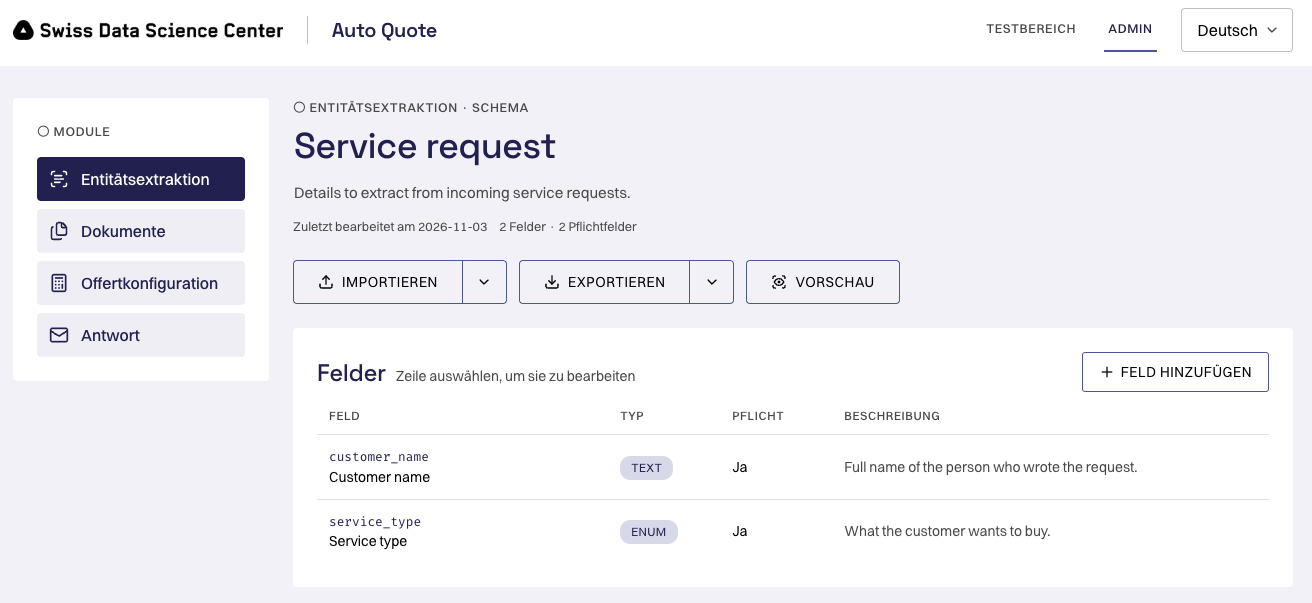

## Vom Notebook zur Anwendung: Warum eine Konfigurationsdatei?

In diesem Notebook haben wir das JSON-Schema von Hand geschrieben. In Auto-Quote soll aber jemand ohne Programmierkenntnisse neue Felder anlegen können, direkt im Frontend unter **Admin → Schema** (Bezeichnung, Typ, Beschreibung, zulässige Werte, Pflichtfeld). Was dort auf dem Bildschirm steht, wird als einfache JSON-Datei gespeichert, mit einem Eintrag pro Feld:

```json
{
    "key": "service_type",
    "label": "Dienstleistungsart",
    "type": "enum",
    "is_required": true,
    "description": "Was der Kunde kaufen möchte.",
    "allowed_values": ["Velounterstand", "Carport", "Beratung"]
}
```

Bei jeder Anfrage erzeugt das Backend daraus automatisch das strikte JSON-Schema aus Abschnitt 4 und den Prompt. Aus diesen 8 Zeilen werden rund 50 Zeilen Schema: `"required"`, `"additionalProperties": false`, `null` für fehlende Werte, und zusätzlich zu jedem Wert ein Beleg (`evidence`) und ein Status (gefunden, angenommen, unvollständig, fehlt).

Warum nicht gleich das JSON-Schema im Frontend bearbeiten?

- **Die Datei enthält nur, was ein Mensch entscheiden muss.** Welche Felder, welche Typen, welche Werte. Die technischen Regeln, die die API für ein striktes Schema verlangt, ergänzt der Code, und zwar jedes Mal gleich. Niemand kann sie vergessen oder falsch schreiben.
- **Eine einzige Quelle.** Das Formular, das Schema und der Prompt entstehen alle aus derselben Datei. Sie können nicht auseinanderlaufen.
- **Fehler werden früh abgefangen.** Ein doppelter Schlüssel oder ein Enum ohne zulässige Werte wird beim Speichern gemeldet, nicht erst, wenn das Modell eine seltsame Antwort liefert.
- **Änderungen ohne neue Software-Version.** Ein neues Feld gilt ab der nächsten Anfrage. Die Datei lässt sich als JSON oder Excel exportieren, sichern, teilen und wieder importieren.

Unter **Vorschau → Strukturierte Ausgabe** zeigt das Frontend das erzeugte Schema an. So lässt sich jederzeit nachprüfen, was tatsächlich an das Sprachmodell geht.